In [66]:
import pandas as pd

In [67]:
import numpy as np

In [68]:
import matplotlib.pyplot as plt 

In [69]:
import seaborn as sn

In [70]:
from sklearn.model_selection import train_test_split

In [71]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

In [72]:
train_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [73]:
test_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [74]:
train_df.shape

(1460, 81)

In [75]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [76]:
train_df.index

RangeIndex(start=0, stop=1460, step=1)

In [77]:
train_df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [78]:
target = 'SalePrice'

In [79]:
x = train_df.drop(columns = [target])

In [80]:
y = train_df[target]

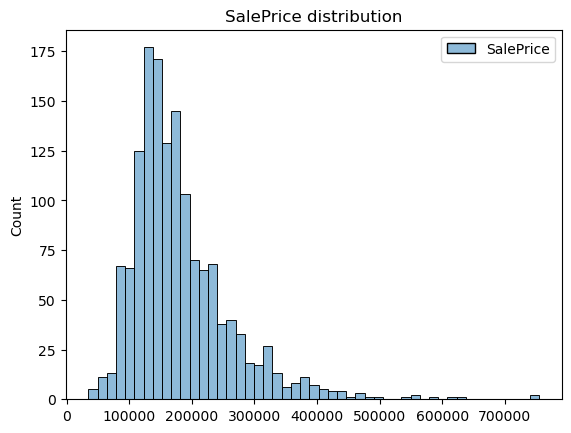

In [81]:
sn.histplot(train_df[['SalePrice']])
plt.title('SalePrice distribution')
plt.savefig('SalePrice distribution.png')
plt.show()

In [82]:
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=0.2, random_state=42)

In [83]:
print(len(x_train), len(x_val), len(y_train), len(y_val))

1168 292 1168 292


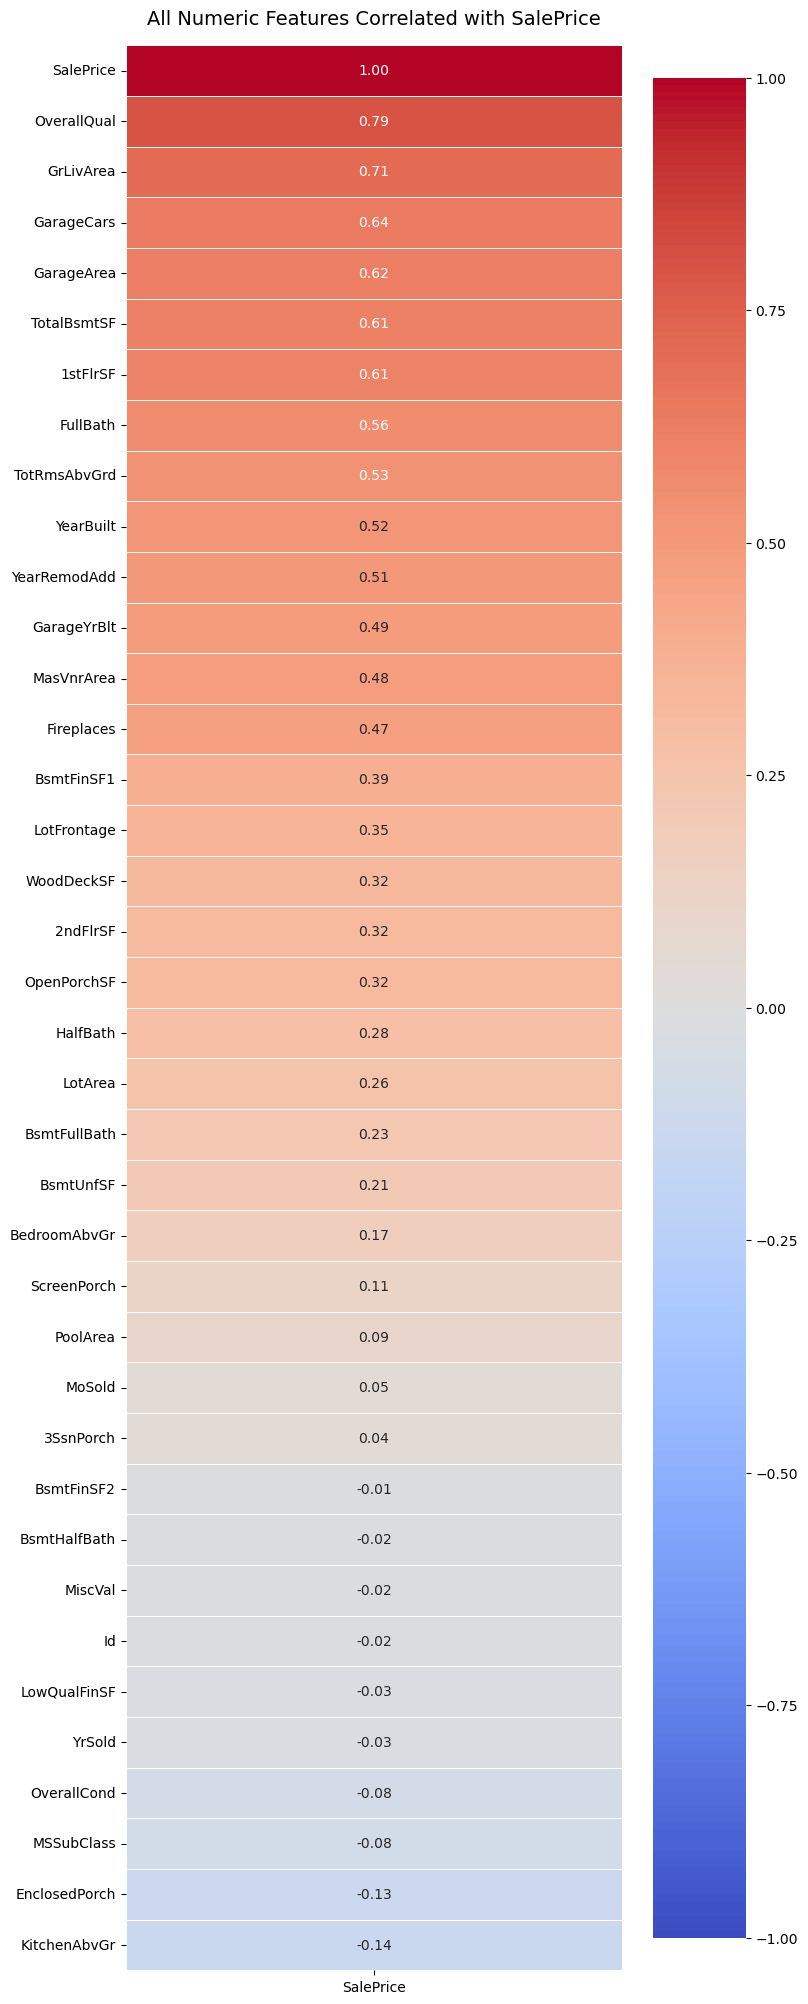

In [84]:
plt.figure(figsize=(8, 25))
corr_matrix = train_df.corr(numeric_only=True)
all_corr = corr_matrix[['SalePrice']].sort_values(by='SalePrice', ascending=False)
sn.heatmap(all_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f', linewidths=0.5)
plt.title('All Numeric Features Correlated with SalePrice', fontsize=14, pad=15)
plt.savefig("correlation.png")
plt.show()

In [85]:
low_corr_cols = ['Id', 'BsmtFinSF2', 'LowQualFinSF', 'BsmtHalfBath', 'MiscVal', 
                 'YrSold', 'MoSold', '3SsnPorch', 'PoolArea']
train_df = train_df.drop(columns=low_corr_cols)

In [86]:
train_df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,ScreenPorch,PoolQC,Fence,MiscFeature,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,61,0,0,NaN,NaN,NaN,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,298,0,0,0,NaN,NaN,NaN,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,42,0,0,NaN,NaN,NaN,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,35,272,0,NaN,NaN,NaN,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,192,84,0,0,NaN,NaN,NaN,WD,Normal,250000


In [87]:
numerical_features = x_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

In [88]:
ordinal_features = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 
                    'HeatingQC', 'KitchenQual', 'FireplaceQu', 
                    'GarageQual', 'GarageCond']
qual_values = ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']

In [89]:
numerical_features = x_train.select_dtypes(include=['number']).columns.tolist()

In [90]:
nominal_features = [col for col in x_train.select_dtypes(include=['object']).columns if col not in ordinal_features]

In [91]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.ensemble import RandomForestRegressor

In [92]:
num_trans = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")), 
    ("scaler", StandardScaler())
])

In [93]:
nom_trans = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

In [94]:
ord_trans = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="None")), 
    ("encoder", OrdinalEncoder(categories=[qual_values] * len(ordinal_features), handle_unknown="use_encoded_value", unknown_value=-1))
])

In [95]:
preprocessor = ColumnTransformer(transformers=[
    ("numerical_features", num_trans, numerical_features),
    ("ordinal_features", ord_trans, ordinal_features),
    ("nominal_features", nom_trans, nominal_features)
])

In [96]:
reg = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model_regressor", RandomForestRegressor(n_estimators=150, random_state=42))
])

In [97]:
reg.fit(x_train, y_train)

,steps,"[('preprocessor', ...), ('model_regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical_features', ...), ('ordinal_features', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [98]:
y_pred = reg.predict(x_val)

In [109]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score,root_mean_squared_error

In [110]:
print("MAE {}".format(mean_absolute_error(y_val,y_pred))) 

MAE 17457.20066210046


In [111]:
print("MSE {}".format((mean_squared_error(y_val,y_pred))))

MSE 811037602.0996021


In [112]:
print("R2 {}".format(r2_score(y_val,y_pred)))

R2 0.894262958289876


In [113]:
test_pred = reg.predict(test_df)

In [114]:
### Fit on log(price), evaluate with RMSLE (the Kaggle metric)
reg.fit(x_train, np.log1p(y_train)) 
val_pred = reg.predict(x_val)
print("Validation RMSLE:", root_mean_squared_error(np.log1p(y_val), val_pred))

Validation RMSLE: 0.14612105713736023


In [120]:
reg.fit(x_train, np.log1p(y_train))

,steps,"[('preprocessor', ...), ('model_regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical_features', ...), ('ordinal_features', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [123]:
test_pred = np.expm1(reg.predict(test_df))

In [124]:
submission = pd.DataFrame({"Id": test_df["Id"], "SalePrice": test_pred})
submission.to_csv("submission.csv", index=False)
print(submission.shape) 
submission.head()

(1459, 2)


,Id,SalePrice
0,1461,125244.764395
1,1462,150961.164907
2,1463,177697.020153
3,1464,180366.761148
4,1465,195839.960273
